

Notebook này thực hiện 3 bước theo yêu cầu Tuần 2:

1. **Định vị & Khử nghiêng**: Canny → Hough Transform → tính góc lệch → xoay ảnh về 0°
2. **Tách khung bằng Perspective Transform**: tìm 4 góc trang giấy → biến đổi phối cảnh để "phẳng hóa" ảnh chụp bị méo
3. **Tiền xử lý CLAHE**: tăng cường độ tương phản cục bộ cho vùng chữ và vùng sơ đồ thửa đất

Cuối cùng: **tách ảnh đã chuẩn hóa thành 3 vùng ROI** — Văn bản / Sơ đồ thửa đất / Con dấu đỏ.


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math
import os

plt.rcParams["figure.figsize"] = (10, 8)
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)


def show(img, title="", cmap=None):
    plt.figure()
    if img.ndim == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap or "gray")
    plt.title(title)
    plt.axis("off")
    plt.show()


def show_grid(images_titles, cols=3, cmap=None):
    n = len(images_titles)
    rows = math.ceil(n / cols)
    plt.figure(figsize=(5 * cols, 5 * rows))
    for i, (img, title) in enumerate(images_titles):
        plt.subplot(rows, cols, i + 1)
        if img.ndim == 3:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(img, cmap=cmap or "gray")
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

Đã nạp ảnh thật từ: data/so-do-mau.jpg


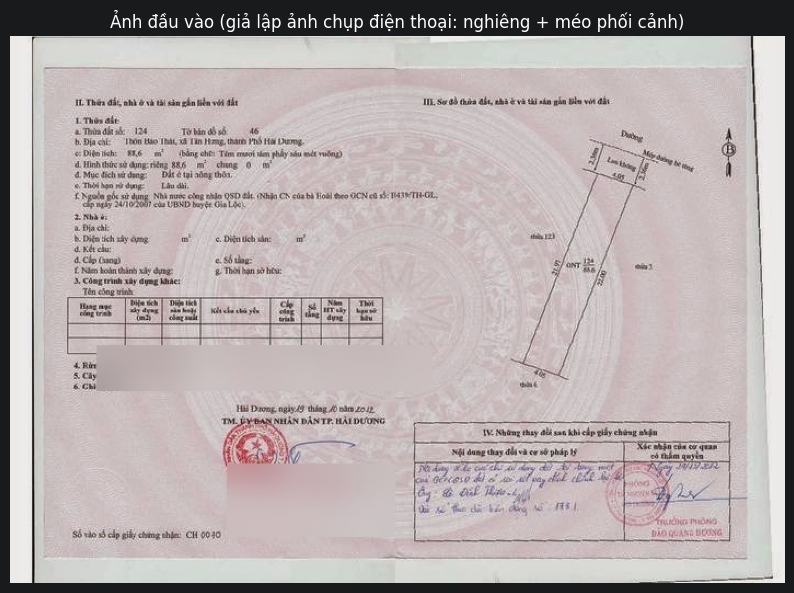

In [2]:


IMAGE_PATH = "data/so-do-mau.jpg"  

if IMAGE_PATH and os.path.exists(IMAGE_PATH):
    image = cv2.imread(IMAGE_PATH)
    print(f"Đã nạp ảnh thật từ: {IMAGE_PATH}")
else:
    image = raw_photo
    cv2.imwrite(os.path.join(OUTPUT_DIR, "00_synthetic_input.jpg"), image)
    print("Chưa cung cấp IMAGE_PATH -> dùng ảnh tổng hợp (synthetic) để demo pipeline.")

show(image, "Ảnh đầu vào (giả lập ảnh chụp điện thoại: nghiêng + méo phối cảnh)")

## 1. Định vị & Khử nghiêng (Canny + Hough Transform)

Quy trình:
1. Chuyển ảnh xám, làm mờ nhẹ để giảm nhiễu
2. Dùng **Canny** để tìm biên toàn bộ ảnh
3. Dùng **Hough Transform** (`cv2.HoughLinesP`) để tìm các đoạn thẳng nổi bật (thường là cạnh trang giấy)
4. Tính góc lệch trung bình (median) của các đoạn thẳng gần-ngang
5. Xoay ảnh ngược lại góc lệch đó để đưa trang giấy về phương ngang (0°)

Góc lệch ước lượng (median trên 77 đoạn thẳng): 0.00 độ


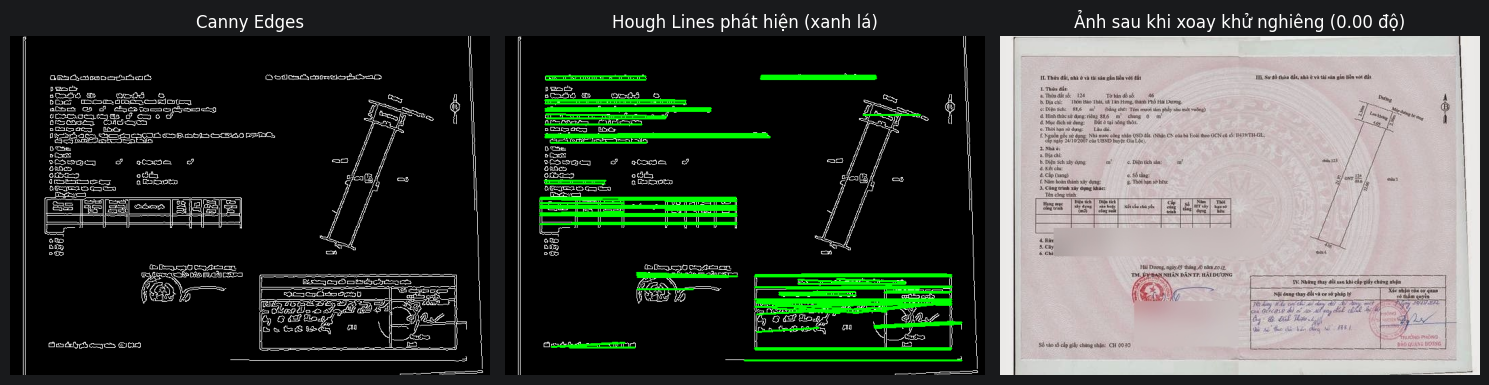

True

In [3]:
def deskew_with_hough(img, canny_low=50, canny_high=150,
                       hough_thresh=80, min_line_len_ratio=0.15, max_line_gap=20):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blur, canny_low, canny_high)

    h, w = gray.shape
    min_line_len = int(min(h, w) * min_line_len_ratio)

    lines = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=hough_thresh,
                             minLineLength=min_line_len, maxLineGap=max_line_gap)

    angles = []
    line_vis = cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)
    if lines is not None:
        for line in lines.reshape(-1, 4):
            x1, y1, x2, y2 = line
            angle = math.degrees(math.atan2(y2 - y1, x2 - x1))
            if -45 < angle < 45:
                angles.append(angle)
                cv2.line(line_vis, (x1, y1), (x2, y2), (0, 255, 0), 2)

    if len(angles) == 0:
        print("Không tìm thấy đường thẳng phù hợp, bỏ qua bước xoay.")
        return img, 0.0, edges, line_vis

    skew_angle = float(np.median(angles))
    print(f"Góc lệch ước lượng (median trên {len(angles)} đoạn thẳng): {skew_angle:.2f} độ")

    (h, w) = img.shape[:2]
    center = (w // 2, h // 2)
    M = cv2.getRotationMatrix2D(center, skew_angle, 1.0)
    rotated = cv2.warpAffine(img, M, (w, h),
                              flags=cv2.INTER_CUBIC,
                              borderMode=cv2.BORDER_REPLICATE)
    return rotated, skew_angle, edges, line_vis


deskewed, angle, edges, line_vis = deskew_with_hough(image)

show_grid([
    (edges, "Canny Edges"),
    (line_vis, "Hough Lines phát hiện (xanh lá)"),
    (deskewed, f"Ảnh sau khi xoay khử nghiêng ({angle:.2f} độ)"),
])

cv2.imwrite(os.path.join(OUTPUT_DIR, "01_edges.jpg"), edges)
cv2.imwrite(os.path.join(OUTPUT_DIR, "02_deskewed.jpg"), deskewed)

## 2. Tách khung bằng Perspective Transform

Sau khi khử nghiêng góc lớn, ảnh có thể vẫn còn méo phối cảnh (chụp không vuông góc với mặt giấy).
Quy trình:
1. Tìm tất cả contour trên ảnh nhị phân (biên Canny sau khi giãn nở nhẹ - dilate)
2. Chọn contour có diện tích lớn nhất và xấp xỉ thành tứ giác 4 điểm (`cv2.approxPolyDP`)
3. Sắp xếp 4 điểm góc theo thứ tự (trên-trái, trên-phải, dưới-phải, dưới-trái)
4. Tính kích thước ảnh đích và áp dụng `cv2.getPerspectiveTransform` + `cv2.warpPerspective`
   để "nắn phẳng" trang giấy thành hình chữ nhật chuẩn.

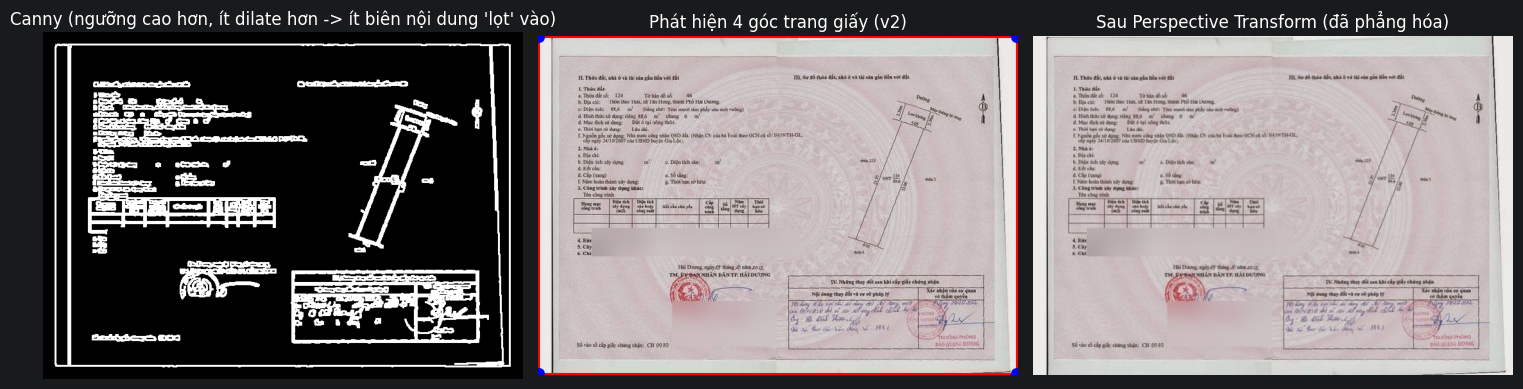

True

In [4]:
def order_points(pts):
    """Sắp xếp 4 điểm: [top-left, top-right, bottom-right, bottom-left]."""
    rect = np.zeros((4, 2), dtype="float32")
    s = pts.sum(axis=1)
    rect[0] = pts[np.argmin(s)]
    rect[2] = pts[np.argmax(s)]
    diff = np.diff(pts, axis=1)
    rect[1] = pts[np.argmin(diff)]
    rect[3] = pts[np.argmax(diff)]
    return rect


def find_document_contour(img, canny_low=60, canny_high=180, dilate_iter=1,
                           min_area_ratio=0.60, pad=20):
    h, w = img.shape[:2]
    padded = cv2.copyMakeBorder(img, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=(0, 0, 0))
    gray = cv2.cvtColor(padded, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blur, canny_low, canny_high)
    if dilate_iter > 0:
        edges = cv2.dilate(edges, np.ones((3, 3), np.uint8), iterations=dilate_iter)

    contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contours = sorted(contours, key=cv2.contourArea, reverse=True)

    for c in contours[:8]:
        if cv2.contourArea(c) < min_area_ratio * h * w:
            continue
        peri = cv2.arcLength(c, True)
        for eps_factor in (0.01, 0.02, 0.03, 0.05):
            approx = cv2.approxPolyDP(c, eps_factor * peri, True)
            if len(approx) != 4 or not cv2.isContourConvex(approx):
                continue
            pts = approx.reshape(4, 2).astype("float32")
            (tl, tr, br, bl) = order_points(pts)
            avg_w = (np.linalg.norm(tr - tl) + np.linalg.norm(br - bl)) / 2
            avg_h = (np.linalg.norm(bl - tl) + np.linalg.norm(br - tr)) / 2
            if avg_h and 0.5 < avg_w / avg_h < 2.2:  
                pts = pts - pad 
                pts[:, 0] = np.clip(pts[:, 0], 0, w - 1)
                pts[:, 1] = np.clip(pts[:, 1], 0, h - 1)
                return pts, edges

    print("Không tìm được tứ giác trang giấy hợp lệ -> coi cả khung ảnh là trang giấy.")
    full = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
    return full, edges


def four_point_transform(img, pts, out_w=None, out_h=None):
    rect = order_points(np.array(pts, dtype="float32"))
    (tl, tr, br, bl) = rect

    widthA = np.linalg.norm(br - bl)
    widthB = np.linalg.norm(tr - tl)
    maxWidth = out_w or int(max(widthA, widthB))

    heightA = np.linalg.norm(tr - br)
    heightB = np.linalg.norm(tl - bl)
    maxHeight = out_h or int(max(heightA, heightB))

    dst = np.array([
        [0, 0],
        [maxWidth - 1, 0],
        [maxWidth - 1, maxHeight - 1],
        [0, maxHeight - 1]], dtype="float32")

    M = cv2.getPerspectiveTransform(rect, dst)
    warped = cv2.warpPerspective(img, M, (maxWidth, maxHeight))
    return warped


doc_corners, contour_edges = find_document_contour(deskewed)

contour_vis = deskewed.copy()
if doc_corners is not None:
    cv2.polylines(contour_vis, [doc_corners.astype(int)], True, (0, 0, 255), 4)
    for (x, y) in doc_corners.astype(int):
        cv2.circle(contour_vis, (x, y), 10, (255, 0, 0), -1)

    flattened = four_point_transform(deskewed, doc_corners)
else:
    print("Không xác định được 4 góc trang giấy -> dùng lại ảnh đã khử nghiêng.")
    flattened = deskewed

show_grid([
    (contour_edges, "Canny (ngưỡng cao hơn, ít dilate hơn -> ít biên nội dung 'lọt' vào)"),
    (contour_vis, "Phát hiện 4 góc trang giấy (v2)"),
    (flattened, "Sau Perspective Transform (đã phẳng hóa)"),
])

cv2.imwrite(os.path.join(OUTPUT_DIR, "03_contour.jpg"), contour_vis)
cv2.imwrite(os.path.join(OUTPUT_DIR, "04_flattened.jpg"), flattened)

## 3. Tiền xử lý độ tương phản với CLAHE

CLAHE (Contrast Limited Adaptive Histogram Equalization) tăng tương phản **cục bộ theo từng ô lưới nhỏ**,
giúp:
- Làm nổi bật chữ in bị mờ / ố vàng do photo cũ
- Tăng độ sắc nét đường nét của sơ đồ thửa đất (các đường ranh giới mảnh, dễ bị mất chi tiết)

Áp dụng CLAHE lên kênh **L (độ sáng)** của không gian màu **LAB** để giữ nguyên màu sắc gốc
(đặc biệt là màu đỏ của con dấu, không bị ảnh hưởng).

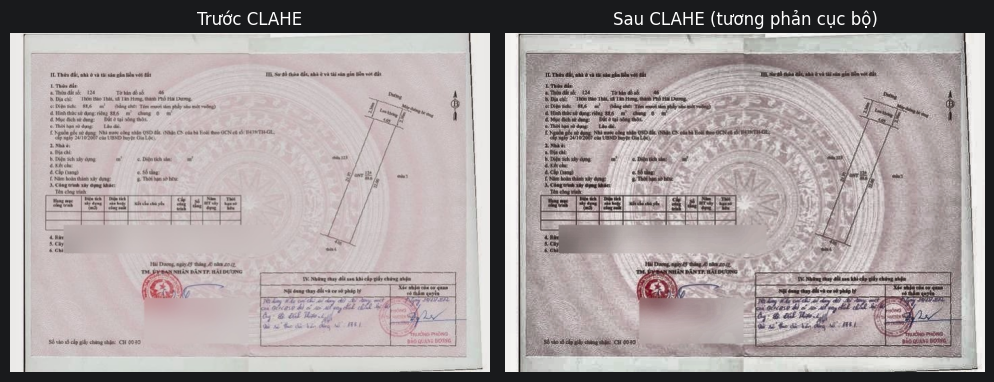

True

In [5]:
def apply_clahe(img, clip_limit=3.0, tile_grid_size=(8, 8)):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    l_enhanced = clahe.apply(l)

    lab_enhanced = cv2.merge((l_enhanced, a, b))
    result = cv2.cvtColor(lab_enhanced, cv2.COLOR_LAB2BGR)
    return result


enhanced = apply_clahe(flattened)

show_grid([
    (flattened, "Trước CLAHE"),
    (enhanced, "Sau CLAHE (tương phản cục bộ)"),
])

cv2.imwrite(os.path.join(OUTPUT_DIR, "05_clahe_enhanced.jpg"), enhanced)

## 4. Phân vùng ROI: Văn bản / Sơ đồ thửa đất / Con dấu đỏ

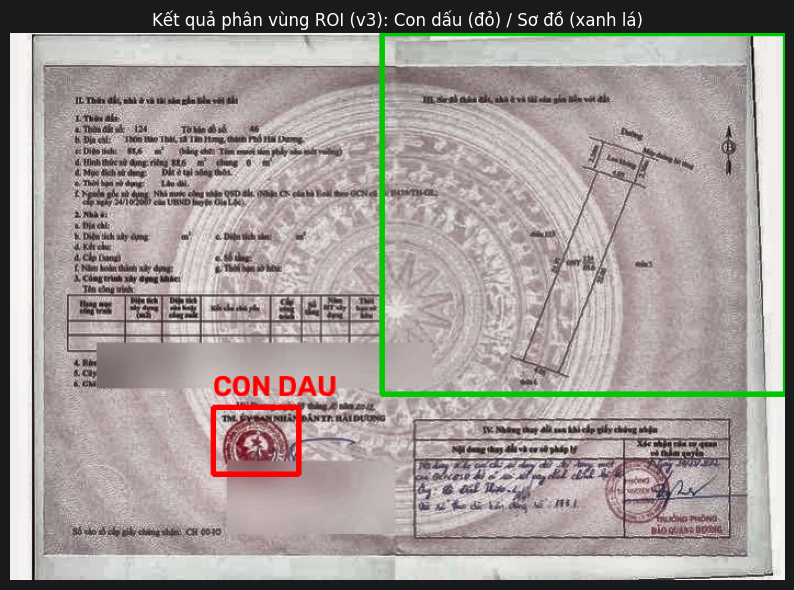

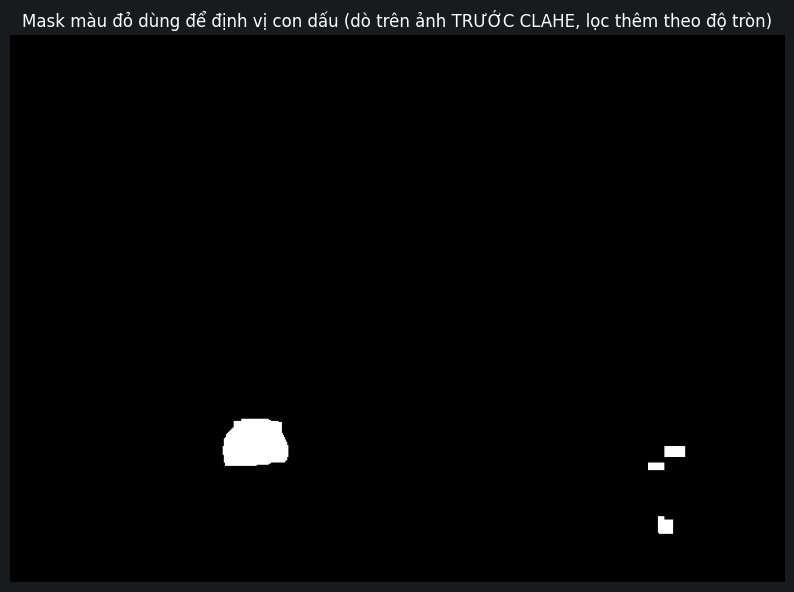

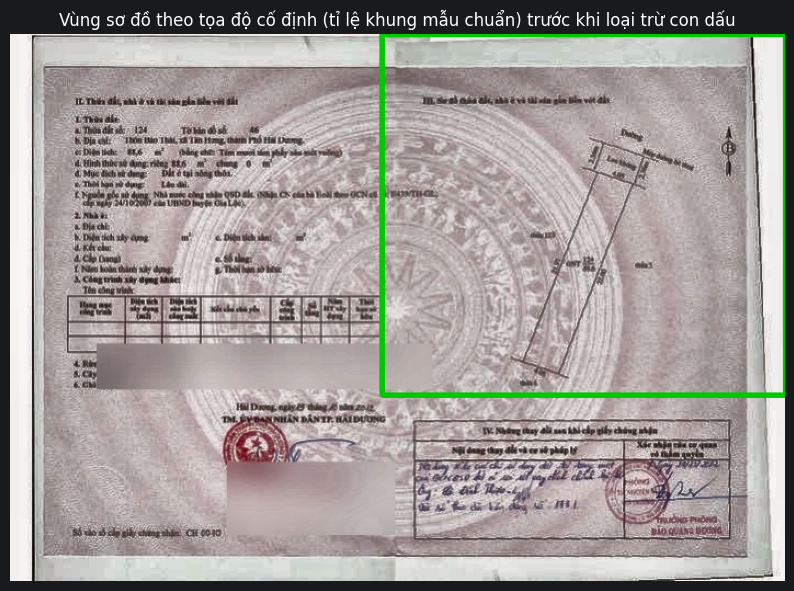

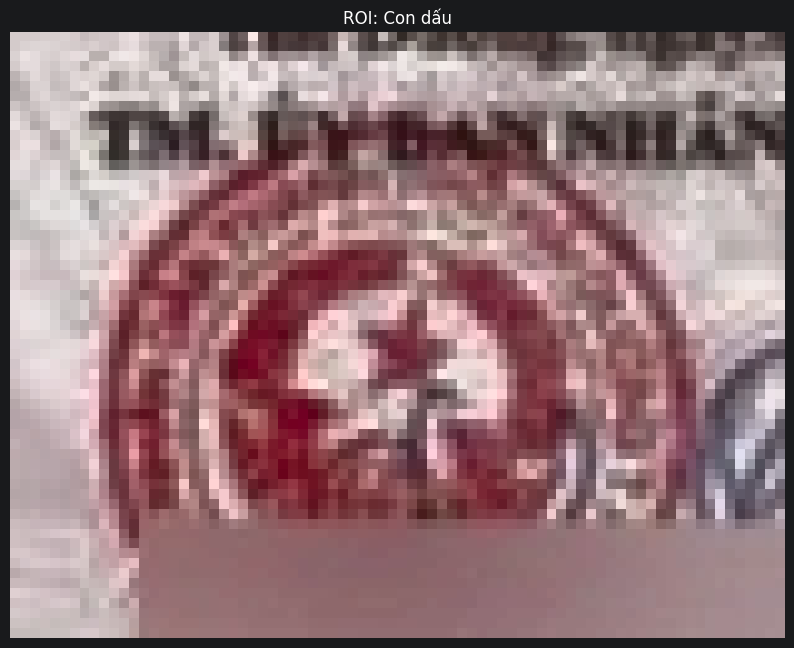

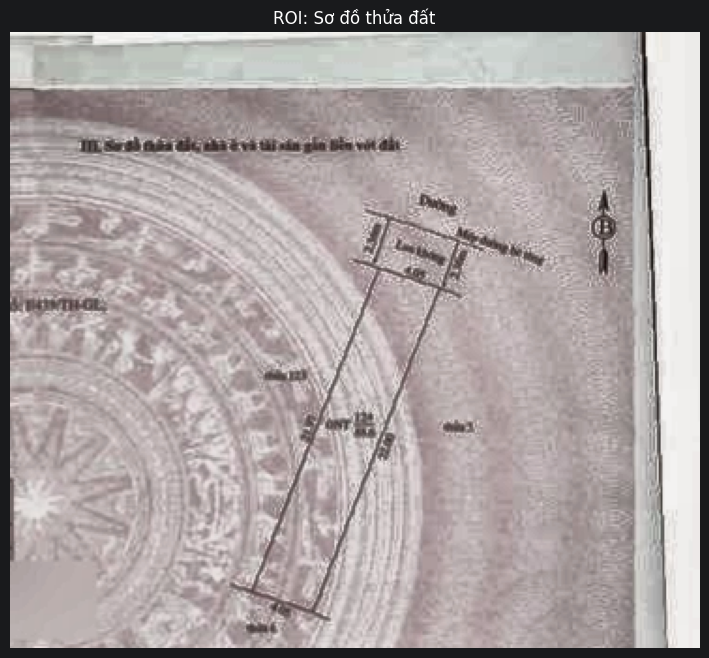

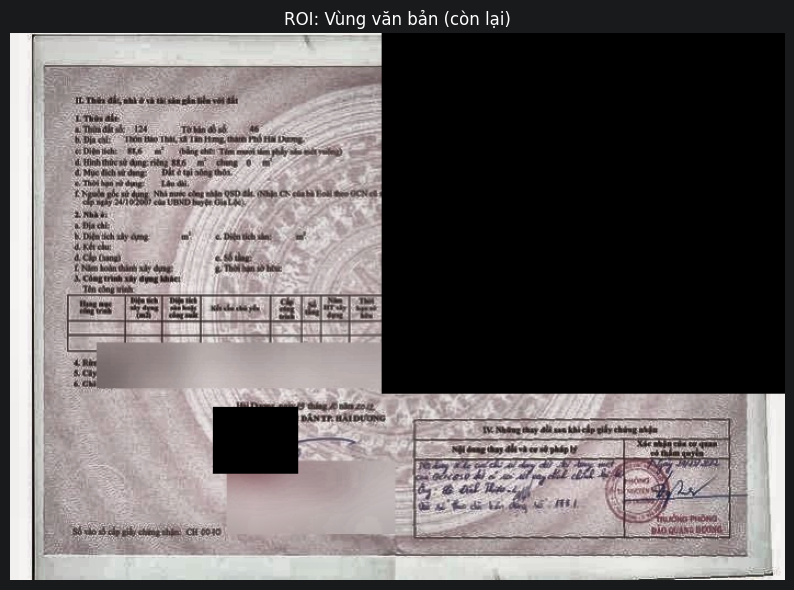

In [6]:
def detect_red_stamp(img, min_area_ratio=0.0015, min_circularity=0.45):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    lower_red1 = np.array([0, 60, 40])
    upper_red1 = np.array([10, 255, 255])
    lower_red2 = np.array([160, 60, 40])
    upper_red2 = np.array([180, 255, 255])

    mask1 = cv2.inRange(hsv, lower_red1, upper_red1)
    mask2 = cv2.inRange(hsv, lower_red2, upper_red2)
    mask = cv2.bitwise_or(mask1, mask2)

    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((21, 21), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    img_area = img.shape[0] * img.shape[1]

    candidates = []
    for c in contours:
        area = cv2.contourArea(c)
        if area < min_area_ratio * img_area:
            continue
        perimeter = cv2.arcLength(c, True)
        if perimeter == 0:
            continue
        circularity = 4 * np.pi * area / (perimeter ** 2)
        x, y, w, h = cv2.boundingRect(c)
        aspect = w / float(h) if h > 0 else 0
        if circularity > min_circularity and 0.6 < aspect < 1.6:
            candidates.append((circularity, area, (x, y, w, h)))

    if not candidates:
        blurred_mask = cv2.GaussianBlur(mask, (9, 9), 2)
        circles = cv2.HoughCircles(blurred_mask, cv2.HOUGH_GRADIENT, dp=1.2,
                                    minDist=min(img.shape[:2]) // 3,
                                    param1=50, param2=25,
                                    minRadius=int(0.03 * min(img.shape[:2])),
                                    maxRadius=int(0.20 * min(img.shape[:2])))
        if circles is None:
            return None, mask
        cx, cy, r = circles[0][0]
        x, y, w, h = int(cx - r), int(cy - r), int(2 * r), int(2 * r)
        x, y = max(0, x), max(0, y)
        w = min(img.shape[1] - x, w)
        h = min(img.shape[0] - y, h)
        return (x, y, w, h), mask

    candidates.sort(key=lambda t: (round(t[0], 2), t[1]), reverse=True)
    _, _, (x, y, w, h) = candidates[0]
    pad = int(0.15 * max(w, h))
    x, y = max(0, x - pad), max(0, y - pad)
    w = min(img.shape[1] - x, w + 2 * pad)
    h = min(img.shape[0] - y, h + 2 * pad)
    return (x, y, w, h), mask


def _detect_diagram_region_by_diagonal_lines_EXPERIMENTAL(img, exclude_boxes=None, win=200,
                                                            stride=100, border_margin_ratio=0.03):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    h, w = edges.shape
    min_line_len = max(20, int(0.06 * min(h, w)))
    lines = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=40,
                             minLineLength=min_line_len, maxLineGap=8)
    margin_x, margin_y = int(border_margin_ratio * w), int(border_margin_ratio * h)
    exclude_boxes = exclude_boxes or []
    weighted_points = []
    line_vis = img.copy()
    if lines is not None:
        for line in lines:
            x1, y1, x2, y2 = line[0]
            if (x1 < margin_x and x2 < margin_x) or (x1 > w - margin_x and x2 > w - margin_x):
                continue
            if (y1 < margin_y and y2 < margin_y) or (y1 > h - margin_y and y2 > h - margin_y):
                continue
            mx, my = (x1 + x2) // 2, (y1 + y2) // 2
            if any(ex <= mx <= ex + ew and ey <= my <= ey + eh for (ex, ey, ew, eh) in exclude_boxes):
                continue
            angle = abs(math.degrees(math.atan2(y2 - y1, x2 - x1))) % 180
            dist_from_axis = min(angle, abs(angle - 90), abs(angle - 180))
            weight = 1.0 + (dist_from_axis / 45.0) * 2.0
            weighted_points.append((mx, my, weight))
            color = (0, 140, 255) if dist_from_axis > 15 else (255, 180, 0)
            cv2.line(line_vis, (x1, y1), (x2, y2), color, 2)
    if not weighted_points:
        return None, line_vis
    best_score, best_box = -1.0, None
    for y in range(0, max(1, h - win), stride):
        for x in range(0, max(1, w - win), stride):
            score = sum(wgt for (mx, my, wgt) in weighted_points if x <= mx < x + win and y <= my < y + win)
            if score > best_score:
                best_score, best_box = score, (x, y, win, win)
    if best_box is None or best_score <= 0:
        return None, line_vis
    x, y, bw, bh = best_box
    pad = int(win * 0.5)
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(w, x + bw + pad), min(h, y + bh + pad)
    return (x0, y0, x1 - x0, y1 - y0), line_vis


def detect_diagram_region(img, exclude_boxes=None,
                           x_start=0.48, y_start=0.0, x_end=1.0, y_end=0.66):
    h, w = img.shape[:2]
    x0, y0 = int(x_start * w), int(y_start * h)
    x1, y1 = int(x_end * w), int(y_end * h)

    box = (x0, y0, x1 - x0, y1 - y0)
    if exclude_boxes:
        for (ex, ey, ew, eh) in exclude_boxes:
            cx, cy = ex + ew / 2, ey + eh / 2
            if x0 <= cx <= x1 and y0 <= cy <= y1:
                print("Cảnh báo: vùng loại trừ (con dấu) nằm chồng lên vùng sơ đồ theo layout mặc định "
                      "-> cân nhắc chỉnh lại x_start/y_start/x_end/y_end cho đúng mẫu giấy tờ của bạn.")

    debug_vis = img.copy()
    cv2.rectangle(debug_vis, (x0, y0), (x1, y1), (0, 200, 0), 3)
    return box, debug_vis


def segment_rois(img, color_source=None):
    color_source = img if color_source is None else color_source

    stamp_box, red_mask = detect_red_stamp(color_source)
    exclude = [stamp_box] if stamp_box else []
    diagram_box, line_vis = detect_diagram_region(img, exclude_boxes=exclude)

    rois = {}
    vis = img.copy()

    if stamp_box:
        x, y, w, h = stamp_box
        rois["con_dau"] = img[y:y + h, x:x + w]
        cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 0, 255), 4)
        cv2.putText(vis, "CON DAU", (x, max(0, y - 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 255), 2)

    if diagram_box:
        x, y, w, h = diagram_box
        rois["so_do"] = img[y:y + h, x:x + w]
        cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 200, 0), 4)
        cv2.putText(vis, "SO DO THUA DAT", (x, max(0, y - 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 200, 0), 2)

    mask_full = np.ones(img.shape[:2], dtype=np.uint8) * 255
    if stamp_box:
        x, y, w, h = stamp_box
        mask_full[y:y + h, x:x + w] = 0
    if diagram_box:
        x, y, w, h = diagram_box
        mask_full[y:y + h, x:x + w] = 0
    rois["van_ban_mask"] = mask_full
    text_only = cv2.bitwise_and(img, img, mask=mask_full)
    rois["van_ban"] = text_only

    return rois, vis, red_mask, line_vis

rois, roi_vis, red_mask, diagram_line_vis = segment_rois(enhanced, color_source=flattened)

show(roi_vis, "Kết quả phân vùng ROI (v3): Con dấu (đỏ) / Sơ đồ (xanh lá)")
show(red_mask, "Mask màu đỏ dùng để định vị con dấu (dò trên ảnh TRƯỚC CLAHE, lọc thêm theo độ tròn)")
show(diagram_line_vis, "Vùng sơ đồ theo tọa độ cố định (tỉ lệ khung mẫu chuẩn) trước khi loại trừ con dấu")

if "con_dau" in rois:
    show(rois["con_dau"], "ROI: Con dấu")
if "so_do" in rois:
    show(rois["so_do"], "ROI: Sơ đồ thửa đất")
show(rois["van_ban"], "ROI: Vùng văn bản (còn lại)")

## 5. Lưu kết quả

In [7]:
cv2.imwrite(os.path.join(OUTPUT_DIR, "06_roi_visualization.jpg"), roi_vis)
if "con_dau" in rois:
    cv2.imwrite(os.path.join(OUTPUT_DIR, "roi_con_dau.jpg"), rois["con_dau"])
if "so_do" in rois:
    cv2.imwrite(os.path.join(OUTPUT_DIR, "roi_so_do.jpg"), rois["so_do"])
cv2.imwrite(os.path.join(OUTPUT_DIR, "roi_van_ban.jpg"), rois["van_ban"])

print("Đã lưu toàn bộ ảnh kết quả vào thư mục:", OUTPUT_DIR)
print(os.listdir(OUTPUT_DIR))

Đã lưu toàn bộ ảnh kết quả vào thư mục: outputs
['01_edges.jpg', '02_deskewed.jpg', '03_contour.jpg', '04_flattened.jpg', '05_clahe_enhanced.jpg', '06_roi_visualization.jpg', 'roi_con_dau.jpg', 'roi_so_do.jpg', 'roi_van_ban.jpg']


## Tổng kết pipeline

| Bước | Kỹ thuật | Input -> Output |
|---|---|---|
| 1. Khử nghiêng | Canny + HoughLinesP + xoay ảnh | Ảnh gốc -> Ảnh đã xoay thẳng |
| 2. Phẳng hóa | Contour + approxPolyDP + Perspective Transform | Ảnh đã xoay -> Ảnh phẳng, đúng tỉ lệ |
| 3. Tăng tương phản | CLAHE trên kênh L (LAB) | Ảnh phẳng -> Ảnh rõ nét hơn |
| 4. Tách ROI | HSV mask (đỏ) + circularity (dấu); Hough đường chéo dài (sơ đồ) | Ảnh đã tăng cường -> 3 vùng: Con dấu / Sơ đồ / Văn bản |
